## Example Scoring Notebook for Log Loss
### A confidence for the presence of an attack must be specified for each observation. If they are provided as binary, we will truncate them for you. 
### The possible range of confidence is (0,1) noninclusive.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.metrics import log_loss
plt.rcParams["figure.figsize"] = (10,6)


/Users/joshem/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


##### Files in ".mat" format can be loaded directly as a dictionary using loadmat from scipy.io.

In [3]:
truth_data=loadmat('TruthData.mat')

##### The truth data will be a part of that dictionary with "AttackTruth" as the key.

In [4]:
truth_series=truth_data['AttackTruth']

##### The loaded data needs to be flattened.

In [5]:
truth_series_flattened=np.concatenate(truth_series).tolist()

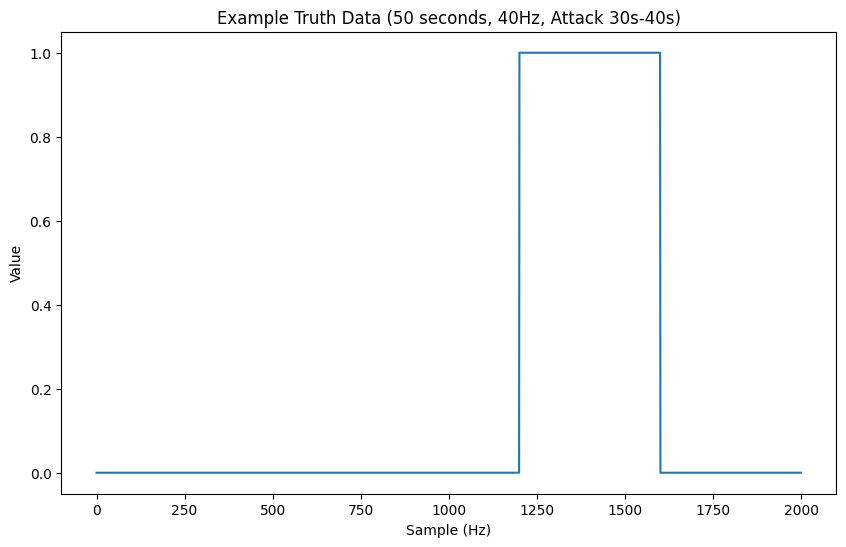

In [6]:
plt.plot(truth_series_flattened)
plt.title("Example Truth Data (50 seconds, 40Hz, Attack 30s-40s)")
plt.xlabel("Sample (Hz)")
plt.ylabel("Value")
plt.show()

##### A synthetic "good prediction": the indices in which an attack is detected are correct. 

In [7]:
def test_prediction_generator(offset):
    return [(lambda x: .01+offset if x <=1200 or x>=1600 else .99-offset)(x) for x in range(2000)]

Text(0.5, 0, 'Sample (Hz)')

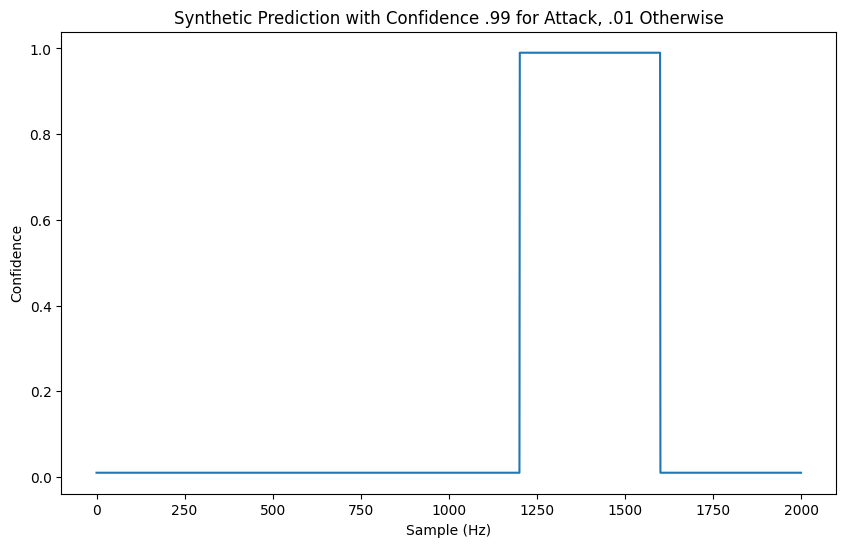

In [8]:
plt.plot(test_prediction_generator(offset=0))
plt.title("Synthetic Prediction with Confidence .99 for Attack, .01 Otherwise")
plt.ylabel("Confidence")
plt.xlabel("Sample (Hz)")

##### Here, we vary the confidence accuracy with an offset to see what happens to the score.

In [9]:
offsets=[0,.05,.10,.15, .20, .25, .30, .35]
progressively_worse_predictions=[test_prediction_generator(_offset) for _offset in offsets]

In [11]:
# Log loss is not symmetric, predictions (confidence) is the second argument.
evaluated_scores=[log_loss(truth_series_flattened,prediction) for prediction in progressively_worse_predictions]

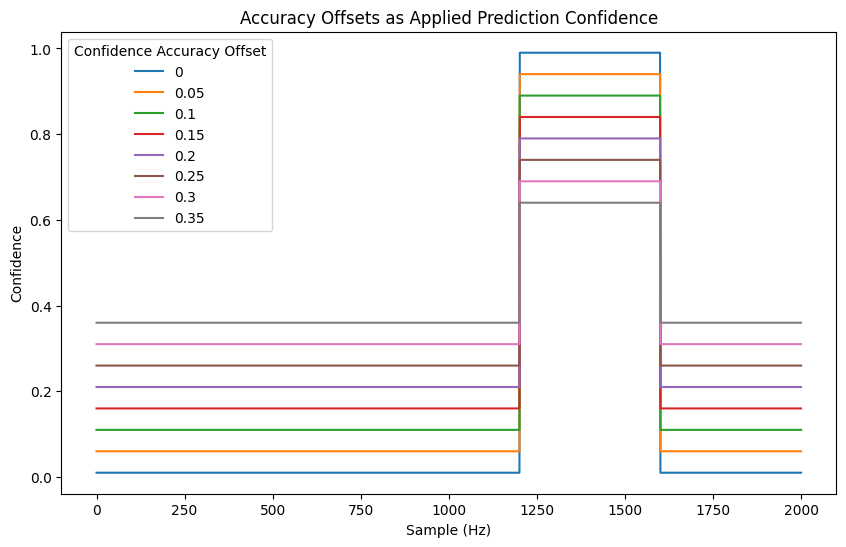

In [12]:
fig = plt.gcf()
ax = plt.gca()
for index, offset in enumerate(offsets):
    ax.plot(progressively_worse_predictions[index], label=str(offsets[index]))
line_colors = [line.get_color() for line in ax.get_lines()]
plt.title("Accuracy Offsets as Applied Prediction Confidence")
plt.legend(title="Confidence Accuracy Offset")
plt.ylabel("Confidence")
plt.xlabel("Sample (Hz)")
plt.show()


Text(0.5, 0, 'Offset')

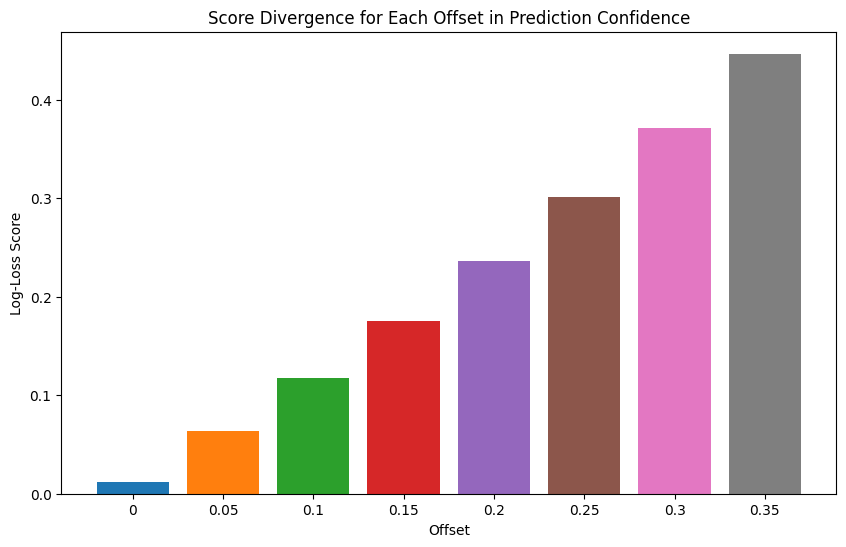

In [13]:
plt.bar([str(x) for x in offsets],evaluated_scores, color=line_colors)
plt.title("Score Divergence for Each Offset in Prediction Confidence")
plt.ylabel("Log-Loss Score")
plt.xlabel("Offset")